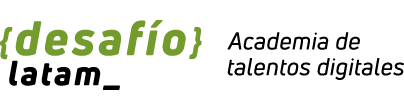

# <center><font color ='green'>Modelos de ensamble</font></center>

Ajustaremos un modelo de ensamble Bagging y un Random Forest para datos de precios de viviendas de Boston, para comparar sus respectivos rendimientos. Utilizaremos para esto una base de datos con información referente a las viviendas y el barrio en el que estan ubicadas. El objetivo es predecir el precio mediano de una vivienda, con la información de sus predictores.

Las variables presentes en el dataset son:

1. CRIM: tasa de delincuencia per cápita por ciudad
2. ZN: proporción de suelo residencial con parcelas de más de 25.000 pies cuadrados.
3. INDUS: proporción de acres comerciales no minoristas por ciudad
4. CHAS: variable ficticia Charles River (1 si la zona colinda con el río; 0 en caso contrario)
5. NOX: concentración de óxidos nítricos (partes por 10 millones).
6. RM: número medio de habitaciones por vivienda
7. EDAD: proporción de unidades ocupadas por sus propietarios construidas antes de 1940
8. DIS: distancias ponderadas a cinco centros de empleo de Boston
9. RAD: índice de accesibilidad a autopistas radiales
10. TAX: tipo del impuesto sobre bienes inmuebles por cada 10.000 $ [$/10k].
11. PTRATIO: ratio alumnos-profesor por ciudad
12. B: resultado de la ecuación B=1000(Bk - 0,63)^2 donde Bk es la proporción de personas de color por ciudad
13. LSTAT: % de estatus inferior de la población

Variable de salida:
1) MEDV: Valor mediano de las viviendas ocupadas por sus propietarios en miles de '$'.

## Carga de bibliotecas y datos

- r2_score -> cuanto explica el modelo la varianza del vector objetivo.
- mean_squared_error -> error cuadratico medio
- mean_absolute_error -> error media absoluto, el cual es muy facil de interpretar. Supongamos que el error medio absoluto del modelo es de 2000. Esto significa si la casa te cuesta 200,000, podría costar 198,000 o 202,000.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
# DecisionTreeRegressor -> Arbol de decision regresivo
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor, BaggingClassifier, RandomForestClassifier
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.model_selection import GridSearchCV

df = pd.read_csv('boston.csv')
df.sample(10)

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
10,0.22489,12.5,7.87,0,0.524,6.377,94.3,6.3467,5,311.0,15.2,392.52,20.45,15.0
346,0.06162,0.0,4.39,0,0.442,5.898,52.3,8.0136,3,352.0,18.8,364.61,12.67,17.2
200,0.01778,95.0,1.47,0,0.403,7.135,13.9,7.6534,3,402.0,17.0,384.30,4.45,32.9
93,0.02875,28.0,15.04,0,0.464,6.211,28.9,3.6659,4,270.0,18.2,396.33,6.21,25.0
78,0.05646,0.0,12.83,0,0.437,6.232,53.7,5.0141,5,398.0,18.7,386.40,12.34,21.2
249,0.19073,22.0,5.86,0,0.431,6.718,17.5,7.8265,7,330.0,19.1,393.74,6.56,26.2
323,0.28392,0.0,7.38,0,0.493,5.708,74.3,4.7211,5,287.0,19.6,391.13,11.74,18.5
129,0.88125,0.0,21.89,0,0.624,5.637,94.7,1.9799,4,437.0,21.2,396.90,18.34,14.3
88,0.05660,0.0,3.41,0,0.489,7.007,86.3,3.4217,2,270.0,17.8,396.90,5.50,23.6
308,0.49298,0.0,9.90,0,0.544,6.635,82.5,3.3175,4,304.0,18.4,396.90,4.54,22.8


In [2]:
list(df)

['CRIM',
 'ZN',
 'INDUS',
 'CHAS',
 'NOX',
 'RM',
 'AGE',
 'DIS',
 'RAD',
 'TAX',
 'PTRATIO',
 'B',
 'LSTAT',
 'MEDV']

In [2]:
list(df.items())

[('CRIM',
  0      0.00632
  1      0.02731
  2      0.02729
  3      0.03237
  4      0.06905
          ...   
  501    0.06263
  502    0.04527
  503    0.06076
  504    0.10959
  505    0.04741
  Name: CRIM, Length: 506, dtype: float64),
 ('ZN',
  0      18.0
  1       0.0
  2       0.0
  3       0.0
  4       0.0
         ... 
  501     0.0
  502     0.0
  503     0.0
  504     0.0
  505     0.0
  Name: ZN, Length: 506, dtype: float64),
 ('INDUS',
  0       2.31
  1       7.07
  2       7.07
  3       2.18
  4       2.18
         ...  
  501    11.93
  502    11.93
  503    11.93
  504    11.93
  505    11.93
  Name: INDUS, Length: 506, dtype: float64),
 ('CHAS',
  0      0
  1      0
  2      0
  3      0
  4      0
        ..
  501    0
  502    0
  503    0
  504    0
  505    0
  Name: CHAS, Length: 506, dtype: int64),
 ('NOX',
  0      0.538
  1      0.469
  2      0.469
  3      0.458
  4      0.458
         ...  
  501    0.573
  502    0.573
  503    0.573
  504    0.573
  

In [3]:
# Recodar que en Python True=1 y False=0
True + True + False

2

In [4]:
# contando valores ausentes
[(x1, np.sum(x2.isnull())) for x1, x2 in df.items()]

[('CRIM', 0),
 ('ZN', 0),
 ('INDUS', 0),
 ('CHAS', 0),
 ('NOX', 0),
 ('RM', 0),
 ('AGE', 0),
 ('DIS', 0),
 ('RAD', 0),
 ('TAX', 0),
 ('PTRATIO', 0),
 ('B', 0),
 ('LSTAT', 0),
 ('MEDV', 0)]

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 506 entries, 0 to 505
Data columns (total 14 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   CRIM     506 non-null    float64
 1   ZN       506 non-null    float64
 2   INDUS    506 non-null    float64
 3   CHAS     506 non-null    int64  
 4   NOX      506 non-null    float64
 5   RM       506 non-null    float64
 6   AGE      506 non-null    float64
 7   DIS      506 non-null    float64
 8   RAD      506 non-null    int64  
 9   TAX      506 non-null    float64
 10  PTRATIO  506 non-null    float64
 11  B        506 non-null    float64
 12  LSTAT    506 non-null    float64
 13  MEDV     506 non-null    float64
dtypes: float64(12), int64(2)
memory usage: 55.5 KB


In [6]:
df.shape

(506, 14)

## Segmentación train and test

In [7]:
RSTATE = 23124

X = df.drop(columns=['MEDV'], axis=1)
y = df['MEDV']

X_train , X_test, y_train, y_test = train_test_split(X, y, test_size=.33, random_state=RSTATE)


print(f'X_train: {X_train.shape}')
print(f'X_test: {X_test.shape}')

X_train: (339, 13)
X_test: (167, 13)


## Modelo de Árbol de decisión (Regresión)

In [8]:
model1 = DecisionTreeRegressor(random_state=RSTATE)

# training
model1.fit(X_train, y_train)

# prediction para conjunto de test
yhat_test = model1.predict(X_test)

# prediction para conjunto de train
yhat_train = model1.predict(X_train)

# medir el desempeño del modelo conjunto de train
print('\n---\nConjunto de train')
print(f'r2: {r2_score(y_train, yhat_train)}')
print(f'MAE: {mean_absolute_error(y_train, yhat_train)}')


# medir el desempeño del modelo conjunto de test
print('\n---\nConjunto de test')
print(f'r2: {r2_score(y_test, yhat_test)}')
print(f'MAE: {mean_absolute_error(y_test, yhat_test)}')
print('---\n')


---
Conjunto de train
r2: 1.0
MAE: 0.0

---
Conjunto de test
r2: 0.641465028306524
MAE: 3.183233532934132
---



In [9]:
df['MEDV'].describe()

count    506.000000
mean      22.532806
std        9.197104
min        5.000000
25%       17.025000
50%       21.200000
75%       25.000000
max       50.000000
Name: MEDV, dtype: float64

In [10]:
model1.feature_importances_

array([1.55477539e-02, 4.18123275e-04, 1.53532314e-03, 4.18103483e-04,
       3.97776035e-02, 5.99906332e-01, 1.81608850e-02, 8.55435673e-02,
       2.68886533e-03, 1.36501470e-02, 5.87350463e-03, 2.26293427e-02,
       1.93850448e-01])

In [11]:
pd.DataFrame([X_train.columns, model1.feature_importances_])

,0,1,2,3,4,5,6,7,8,9,10,11,12
0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT
1,0.015548,0.000418,0.001535,0.000418,0.039778,0.599906,0.018161,0.085544,0.002689,0.01365,0.005874,0.022629,0.19385


In [12]:
model1.feature_importances_.sum()

1.0

In [14]:
df['MEDV'].mean()

22.532806324110677

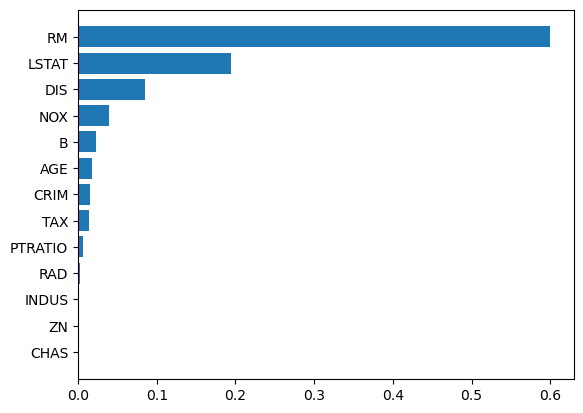

In [15]:
# visualizar importancia de los atributos del modelo

idx_sort = np.argsort(model1.feature_importances_)
plt.barh(y=model1.feature_names_in_[idx_sort], width=model1.feature_importances_[idx_sort]);

In [30]:
idx_sort[-10:-1]

array([ 8, 10,  9,  0,  6, 11,  4,  7, 12])

In [35]:
X_train_deputado = X_train.iloc[:, idx_sort[-9:]]

In [36]:
X_test_deputado = X_test.iloc[:, idx_sort[-9:]]

In [37]:
model1_2 = DecisionTreeRegressor(random_state=RSTATE)

# training
model1_2.fit(X_train_deputado, y_train)

# prediction para conjunto de test
yhat_test_depurado = model1_2.predict(X_test_deputado)

# prediction para conjunto de train
yhat_train_depurado = model1_2.predict(X_train_deputado)

# medir el desempeño del modelo conjunto de train
print('\n---\nConjunto de train')
print(f'r2: {r2_score(y_train, yhat_train_depurado)}')
print(f'MAE: {mean_absolute_error(y_train, yhat_train_depurado)}')


# medir el desempeño del modelo conjunto de test
print('\n---\nConjunto de test')
print(f'r2: {r2_score(y_test, yhat_test_depurado)}')
print(f'MAE: {mean_absolute_error(y_test, yhat_test_depurado)}')
print('---\n')


---
Conjunto de train
r2: 1.0
MAE: 0.0

---
Conjunto de test
r2: 0.6375992899639791
MAE: 3.204191616766467
---



## Modelo de ensamble Bagging

Veremos ahora el funcionamiento de un modelo Bagging, utilizando para ello 100 árboles de regresión. Es posible utilizar también otros modelos predictivos, pero por defecto la función de Python utiliza árboles

In [38]:
%%time
model2 = BaggingRegressor(n_estimators=100, oob_score=True, random_state=RSTATE, n_jobs=-1)

'''
n_estimators=100: indica el número de estimadores (modelos base) en el conjunto.
En este caso, estás utilizando 100 regresores base.

oob_score=True: calcula el rendimiento fuera de la bolsa (out-of-bag score). Es
útil para tener una estimación adicional del rendimiento del modelo sin necesidad
 de un conjunto de prueba separado.

random_state=RSTATE: establece la semilla para la reproducibilidad del modelo.
Si se utiliza la misma semilla, se obtendrán los mismos resultados en cada ejecución.

n_jobs=-1: indica el número de trabajadores (núcleos de CPU) que se utilizarán
para entrenar los modelos base de forma paralela. En este caso, se utiliza -1 para utilizar todos los núcleos disponibles.
'''


# training
model2.fit(X_train, y_train)

# prediccion para conjunto de test
yhat_test = model2.predict(X_test)

# prediccion para conjunto de train
yhat_train = model2.predict(X_train)

# medir el desempeño del modelo conjunto de train
print('\n---\nConjunto de train')
print(f'r2: {r2_score(y_train, yhat_train)}')
print(f'MAE: {mean_absolute_error(y_train, yhat_train)}')


# medir el desempeño del modelo conjunto de test
print('\n---\nConjunto de test')
print(f'r2: {r2_score(y_test, yhat_test)}')
print(f'MAE: {mean_absolute_error(y_test, yhat_test)}')
print('---\n')


---
Conjunto de train
r2: 0.9794700869123841
MAE: 0.8315870206489676

---
Conjunto de test
r2: 0.8609365457843575
MAE: 2.405994011976048
---

CPU times: user 81.9 ms, sys: 83 ms, total: 165 ms
Wall time: 701 ms


### Estimación de r2 con datos OOB

In [39]:
model2.oob_score_

0.8499189758688621

## Modelo de ensamble Random Forest

In [40]:
%%time
model3 = RandomForestRegressor(max_features='sqrt', random_state=RSTATE, oob_score=True, n_jobs=-1) # 100 árboles

# training
model3.fit(X_train, y_train)

# prediction para conjunto de test
yhat_test = model3.predict(X_test)

# prediction para conjunto de test
yhat_train = model3.predict(X_train)

# medir el desempeño del modelo conjunto de train
print('\n---\nConjunto de train')
print(f'r2: {r2_score(y_train, yhat_train)}')
print(f'MAE: {mean_absolute_error(y_train, yhat_train)}')


# medir el desempeño del modelo conjunto de test
print('\n---\nConjunto de test')
print(f'r2: {r2_score(y_test, yhat_test)}')
print(f'MAE: {mean_absolute_error(y_test, yhat_test)}')
print('---\n')


---
Conjunto de train
r2: 0.9799865805096669
MAE: 0.8423864306784636

---
Conjunto de test
r2: 0.8638394852830272
MAE: 2.381994011976046
---

CPU times: user 140 ms, sys: 123 ms, total: 263 ms
Wall time: 151 ms


### Estimación de $r^2$ con datos OOB

In [41]:
model3.oob_score_

0.8530444381962692

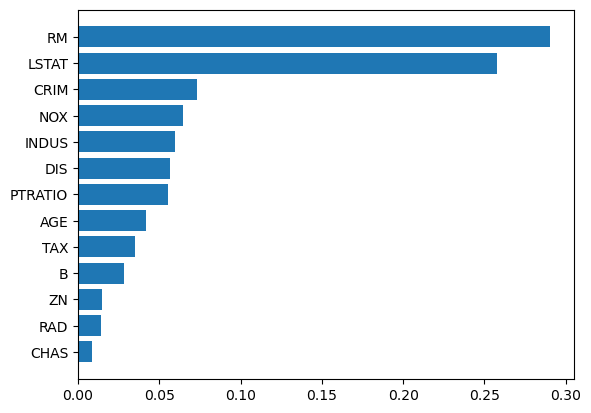

In [42]:
# visualizar importancia de los atributos del modelo

idx_sort = np.argsort(model3.feature_importances_)
plt.barh(y=model3.feature_names_in_[idx_sort], width=model3.feature_importances_[idx_sort]);

## Ajuste de hiper parámetros

In [45]:
 list(np.linspace(50, 200, 50, dtype='int')) +[100]

[50,
 53,
 56,
 59,
 62,
 65,
 68,
 71,
 74,
 77,
 80,
 83,
 86,
 89,
 92,
 95,
 98,
 102,
 105,
 108,
 111,
 114,
 117,
 120,
 123,
 126,
 129,
 132,
 135,
 138,
 141,
 144,
 147,
 151,
 154,
 157,
 160,
 163,
 166,
 169,
 172,
 175,
 178,
 181,
 184,
 187,
 190,
 193,
 196,
 200,
 100]

In [51]:
%%time
# permite medir el tiempo de ejecución de la celda en la que se encuentra. Esto
# dará el tiempo total que lleva ejecutar la búsqueda de hiperparámetros.

param_grid = {
    'n_estimators': np.linspace(50, 200, 50, dtype='int'),
    'max_features': ['sqrt', 'log2', None]
}

'''
Define la cuadrícula de hiperparámetros que se probarán durante la búsqueda.
Estamos probando diferentes valores para el número de estimadores (n_estimators)
 y las características máximas (max_features) en cada árbol.
'''

grid_model4 = GridSearchCV(
    RandomForestRegressor(oob_score=True, random_state=RSTATE),
    param_grid=param_grid,
    n_jobs=-1,
    cv=5,
    verbose=3
)
'''
Se realiza la búsqueda de hiperparámetros utilizando validación cruzada. Se le
pasa el modelo base (RandomForestRegressor con algunos parámetros predeterminados),
 la cuadrícula de hiperparámetros (param_grid), el número de trabajadores a
 utilizar en paralelo (n_jobs=-1 significa utilizar todos los núcleos
 disponibles), y el número de divisiones para la validación cruzada
 (cv=5 significa validación cruzada de 5 pliegues).
'''


grid_model4.fit(X_train, y_train)


Fitting 5 folds for each of 150 candidates, totalling 750 fits
CPU times: user 435 ms, sys: 35.6 ms, total: 471 ms
Wall time: 6.52 s


GridSearchCV(cv=5,
             estimator=RandomForestRegressor(oob_score=True,
                                             random_state=23124),
             n_jobs=-1,
             param_grid={'max_features': ['sqrt', 'log2', None],
                         'n_estimators': array([ 50,  53,  56,  59,  62,  65,  68,  71,  74,  77,  80,  83,  86,
        89,  92,  95,  98, 102, 105, 108, 111, 114, 117, 120, 123, 126,
       129, 132, 135, 138, 141, 144, 147, 151, 154, 157, 160, 163, 166,
       169, 172, 175, 178, 181, 184, 187, 190, 193, 196, 200])},
             verbose=3)

In [50]:
print('\n---')
print('Mejores valores de hiper parámetros encontrados:')
print(grid_model4.best_params_)
print('---\n')


---
Mejores valores de hiper parámetros encontrados:
{'max_features': None, 'n_estimators': 56}
---



In [52]:
# prediction para conjunto de test
yhat_test = grid_model4.best_estimator_.predict(X_test)

# prediction para conjunto de test
yhat_train = grid_model4.best_estimator_.predict(X_train)

# medir el desempeño del modelo conjunto de train
print('\n---\nConjunto de train')
print(f'r2: {r2_score(y_train, yhat_train)}')
print(f'MAE: {mean_absolute_error(y_train, yhat_train)}')


# medir el desempeño del modelo conjunto de test
print('\n---\nConjunto de test')
print(f'r2: {r2_score(y_test, yhat_test)}')
print(f'MAE: {mean_absolute_error(y_test, yhat_test)}')
print('---\n')


---
Conjunto de train
r2: 0.9801202005944047
MAE: 0.8419721871049304

---
Conjunto de test
r2: 0.8664281546625345
MAE: 2.371888366124892
---



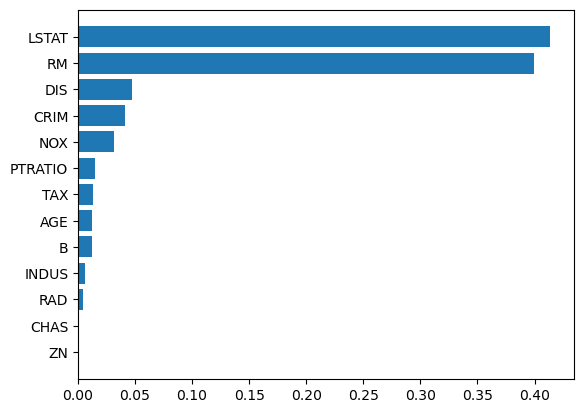

In [53]:
# visualizar importancia de los atributos del modelo
model4 = grid_model4.best_estimator_
idx_sort = np.argsort(model4.feature_importances_)
plt.barh(y=model4.feature_names_in_[idx_sort], width=model4.feature_importances_[idx_sort]);

### Medición de r2 desde datos OOB

In [54]:
model4.oob_score_

0.8472864757565012

### Predicción de un caso particular

In [55]:
# CRIM: 2.24236
# ZN: 0.0
# INDUS: 19.58
# CHAS: 0
# NOX: 0.605
# RM: 5.854
# AGE: 91.8
# DIS: 2.4220
# RAD: 5
# TAX: 403.0
# PTRATIO: 14.7
# B = 395.11
# LSTAT: 11.64

#####
# Valor esperado para la vivienda: 22.7
#####
obs = X_test.loc[[164]]

print('Predicción')
model4.predict(obs)

Predicción


array([21.76607143])

In [56]:
X_test.loc[[164]]

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT
164,2.24236,0.0,19.58,0,0.605,5.854,91.8,2.422,5,403.0,14.7,395.11,11.64


In [57]:
y_test.loc[[164]]

164    22.7
Name: MEDV, dtype: float64

[CV 4/5] END max_features=sqrt, n_estimators=56;, score=0.733 total time=   0.1s
[CV 5/5] END max_features=sqrt, n_estimators=68;, score=0.914 total time=   0.1s
[CV 1/5] END max_features=sqrt, n_estimators=80;, score=0.882 total time=   0.1s
[CV 4/5] END max_features=sqrt, n_estimators=89;, score=0.754 total time=   0.1s
[CV 2/5] END max_features=sqrt, n_estimators=102;, score=0.855 total time=   0.1s
[CV 3/5] END max_features=sqrt, n_estimators=102;, score=0.746 total time=   0.1s
[CV 2/5] END max_features=sqrt, n_estimators=120;, score=0.863 total time=   0.2s
[CV 3/5] END max_features=sqrt, n_estimators=120;, score=0.746 total time=   0.1s
[CV 2/5] END max_features=sqrt, n_estimators=144;, score=0.857 total time=   0.1s
[CV 3/5] END max_features=sqrt, n_estimators=144;, score=0.746 total time=   0.2s
[CV 3/5] END max_features=sqrt, n_estimators=166;, score=0.744 total time=   0.1s
[CV 4/5] END max_features=sqrt, n_estimators=166;, score=0.773 total time=   0.2s
[CV 1/5] END max_fea

### En modelos clasificatorios usar predict_proba para obtner chance de un au otra categoria

rf_model.predict ==> 1

rf_model.predict_proba(X_test)
[0.45, 0.55]

In [ ]:
SVM1 = SupportVectorMachineClassifier()
RL = LogisticRegression()
AD = DesitiDecisionTreeClassifier()
SVM2 = SupportVectorMachineClassifier()

In [ ]:
[SVM1, SVM2, RL, AD]